# Option B — hard bar vs variance-inflation

Implements `SPEC_option_B.md`. Both mechanisms use the settled **per-mode-max** bar; they differ in
*how* the sensitivity coverage is delivered:
- **hardbar** — each policed mode forced `|aₘ| ≥ bₘ` every draw (folded tail, non-Gaussian; the direct sampler).
- **optionB** — each policed mode Gaussian with variance raised to cover it, `σₘ² = max(scale²λₘ, bₘ²)`
  (no truncation; covers `bₘ` in expectation, not per draw).

Judged on **privacy** (projection advantage), **utility**, and — the deciding axis — **statistical
inference validity** (Type-1 / power via `inference_eval`). Frozen core untouched; additive in `bar_study.py`.

## 0 · Setup, frozen check, configuration

In [1]:
import sys, os, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
for c in [".", "work", os.path.expanduser("~/harness")]:
    if os.path.exists(os.path.join(c, "privacy_harness.py")): sys.path.insert(0, c); break
import privacy_harness as ph, mode_eigen_mech as me, tiling as T
import full_release_attacks as fra, bar_study as bs, inference_eval as ie
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
FROZEN = {"privacy_harness.py": "f03e766b265b4b0b253ce3a8eb94cb53ea76662544ea0b1b9db102f8f29015b4",
          "inference_eval.py":  "0bd08830469858a9332a5cfddc6c332a894dc318b09efda42a9ba8fa6c2b2018"}
for f, h in FROZEN.items():
    p = next((os.path.join(c, f) for c in [".", "work", os.path.expanduser("~/harness")]
              if os.path.exists(os.path.join(c, f))), None)
    if p: print(f"  {f}: {'OK' if hashlib.sha256(open(p,'rb').read()).hexdigest()==h else 'CHANGED!'}")

  privacy_harness.py: OK
  inference_eval.py: OK


In [2]:
USE_OASIS = True
N        = 40
PATCH_SIZES = {"3x3x3": (3,3,3), "5x5x5": (5,5,5), "7x7x7": (7,7,7)}
STATS    = ["mean", "median", "variance"]
MECHS    = ["hardbar", "optionB"]
BAR      = "permax"                         # settled by the bar study
TARGETS  = ["istar", "worst"]
SCALES   = [1, 2, 3, 5, 8, 12]
# inference scenario (one-sample t-test): null effect=0 vs alt effect=0.5, equicorr 0.3, p=2 vars
INF = dict(n=N, mc=2000, effect_alt=0.5, corr=0.3, p=2)
for _v in ("OMP_NUM_THREADS","MKL_NUM_THREADS","OPENBLAS_NUM_THREADS","NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
from joblib import Parallel, delayed
N_JOBS = 16; SEED = 0
SIZE = "full" if USE_OASIS else "fast"
BUDG = dict(full=dict(n_trials=4000, n_rel=200, mc=2000), fast=dict(n_trials=1500, n_rel=60, mc=400))[SIZE]
INF["mc"] = BUDG["mc"]
print(f"mechs={MECHS} bar={BAR} scales={SCALES} patches={list(PATCH_SIZES)} | {SIZE}")

mechs=['hardbar', 'optionB'] bar=permax scales=[1, 2, 3, 5, 8, 12] patches=['3x3x3', '5x5x5', '7x7x7'] | full


In [3]:
# substrate (same loader as the bar study)
def gm_mask(volumes):
    from scipy import ndimage as ndi
    gm = np.asarray(volumes, float).mean(0); fin = np.isfinite(gm) & (gm > 0)
    try:
        from skimage.filters import threshold_otsu; thr = float(threshold_otsu(gm[fin]))
    except Exception: thr = float(np.percentile(gm[fin], 60))
    m = ndi.binary_fill_holes(gm > thr); lab, n = ndi.label(m)
    if n > 1:
        sz = ndi.sum(np.ones_like(lab), lab, range(1, n+1)); m = lab == (1 + int(np.argmax(sz)))
    return m & np.isfinite(gm)
if USE_OASIS:
    try:
        SUB = T.load_oasis_volumes(n=max(N+20,100)); VOLS = SUB["volumes"]
        MASK = gm_mask(VOLS); SUBSTRATE = "OASIS gray-matter maps"
    except Exception as e:
        USE_OASIS = False; print("OASIS unavailable ->", repr(e))
if not USE_OASIS:
    SUB = T.make_phantom(shape=(24,24,20), M=2*N+20, N=N, seed=0); VOLS = SUB["volumes"]
    MASK = SUB["mask"]; SUBSTRATE = "synthetic phantom"
def cohort_at(patch):
    src = ph.ArrayBlockSource(VOLS, MASK, block_shape=patch, N=N, seed=SEED)
    return src.sample(N, np.random.default_rng(0)).reshape(N, *patch)
print(f"substrate: {SUBSTRATE} | volumes {VOLS.shape}")

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
substrate: OASIS gray-matter maps | volumes (100, 91, 109, 91)


## 1 · Validation gate

(a) option B is Gaussian with the intended per-mode variance floor `σₘ²=max(scale²λₘ,bₘ²)`;
(b) the inference wrapper gives a clean Type-1 ≈ α at zero noise (so any inflation below is the mechanism).

In [4]:
pool5 = cohort_at(PATCH_SIZES["5x5x5"]); _, D5, _ = ph.loo_artifacts(pool5, ph.pipeline_mean)
ob = bs.OptionBPatchNoise(D5, 3.0, 39, "permax")
Z = ob.sample_batch(20000, np.random.default_rng(1)); A = Z @ ob.Vk
m = bs.build_modes(D5, 3.0, 39, "permax")
print(f"(a) option B per-mode var == sd_B^2: max rel-err {np.max(np.abs(A.var(0)-ob.sd_B**2)/(ob.sd_B**2+1e-12)):.3f}")
print(f"    variance >= bar^2 on policed modes: {bool((ob.sd_B[:39]**2 >= m['bar'][:39]**2 - 1e-9).all())}")
_dfi0 = bs.run_inference([1], mechs=["optionB"], n=INF["n"], mc=max(1000,BUDG['mc']//2), seed=SEED,
                         effect_alt=INF['effect_alt'], corr=INF['corr'], p=INF['p'])
print(f"(b) clean Type-1 (should be ~0.05): {_dfi0['type1_clean'].iloc[0]:.3f}")

(a) option B per-mode var == sd_B^2: max rel-err 0.020
    variance >= bar^2 on policed modes: True
(b) clean Type-1 (should be ~0.05): 0.053


## 2 · Privacy & utility — hardbar vs optionB (per-mode-max bar)

In [5]:
def _job(pn, patch, stat):
    df = bs.run_mech_comparison(cohort_at(patch), stat, SCALES, mechs=MECHS, targets=TARGETS,
                                bar_kind=BAR, n_trials=BUDG["n_trials"], n_rel=BUDG["n_rel"], seed=SEED)
    df.insert(0, "patch", pn); return df
jobs = [(nm, ps, st) for nm, ps in PATCH_SIZES.items() for st in STATS]
PU = pd.concat(Parallel(n_jobs=min(N_JOBS, len(jobs)))(delayed(_job)(nm, ps, st) for nm, ps, st in jobs),
               ignore_index=True)
print("advantage + rel-MSE, target=worst, 5x5x5 (hardbar vs optionB):")
print(PU[(PU.target=="worst") & (PU.patch=="5x5x5")]
      .pivot_table(index=["stat","scale"], columns="mech", values=["adv","rel_mse"]).round(3).to_string())

advantage + rel-MSE, target=worst, 5x5x5 (hardbar vs optionB):
                   adv         rel_mse        
mech           hardbar optionB hardbar optionB
stat     scale                                
mean     1       0.511   0.564   0.001   0.001
         2       0.405   0.564   0.001   0.001
         3       0.307   0.488   0.002   0.001
         5       0.202   0.290   0.004   0.002
         8       0.119   0.179   0.008   0.006
         12      0.103   0.116   0.016   0.013
median   1       0.567   0.683   0.002   0.001
         2       0.469   0.678   0.003   0.001
         3       0.392   0.604   0.005   0.002
         5       0.315   0.417   0.011   0.007
         8       0.253   0.304   0.024   0.018
         12      0.232   0.240   0.049   0.039
variance 1       0.446   0.513   0.032   0.029
         2       0.390   0.513   0.040   0.029
         3       0.328   0.491   0.053   0.030
         5       0.266   0.394   0.089   0.043
         8       0.225   0.272   0.168   0.0

## 3 · Inference validity — the deciding axis

Type-1 (nominal 0.05) and power vs scale:
        power           type1        
mech  hardbar optionB hardbar optionB
scale                                
1       0.827   0.838   0.082   0.067
2       0.812   0.838   0.093   0.067
3       0.795   0.832   0.112   0.075
5       0.760   0.801   0.169   0.126
8       0.712   0.741   0.279   0.230
12      0.682   0.696   0.410   0.368


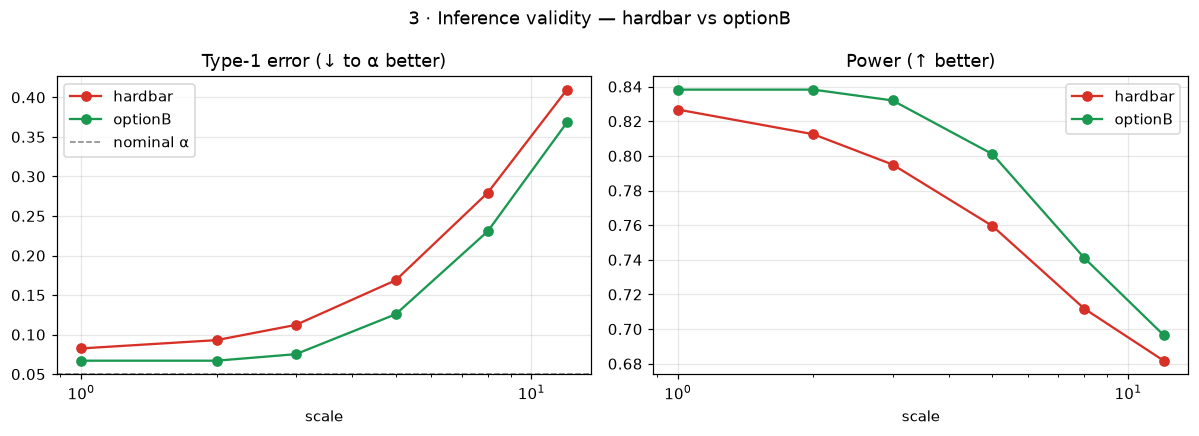

In [6]:
def _inf_job(mech):
    return bs.run_inference(SCALES, mechs=[mech], n=INF["n"], mc=INF["mc"], seed=SEED,
                            effect_alt=INF["effect_alt"], corr=INF["corr"], p=INF["p"])
INFR = pd.concat(Parallel(n_jobs=min(N_JOBS, len(MECHS)))(delayed(_inf_job)(mk) for mk in MECHS),
                 ignore_index=True)
print("Type-1 (nominal 0.05) and power vs scale:")
print(INFR.pivot_table(index="scale", columns="mech", values=["type1","power"]).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for mech, col in zip(MECHS, ["#d73027","#1a9850"]):
    s = INFR[INFR.mech==mech].sort_values("scale")
    ax[0].plot(s.scale, s.type1, "o-", color=col, label=mech)
    ax[1].plot(s.scale, s.power, "o-", color=col, label=mech)
ax[0].axhline(0.05, ls="--", color="grey", lw=1, label="nominal α")
ax[0].set_title("Type-1 error (↓ to α better)"); ax[0].set_xlabel("scale"); ax[0].set_xscale("log"); ax[0].legend()
ax[1].set_title("Power (↑ better)"); ax[1].set_xlabel("scale"); ax[1].set_xscale("log"); ax[1].legend()
fig.suptitle("3 · Inference validity — hardbar vs optionB"); plt.tight_layout(); plt.show()

## 4 · Frontiers — private AND inference-valid?

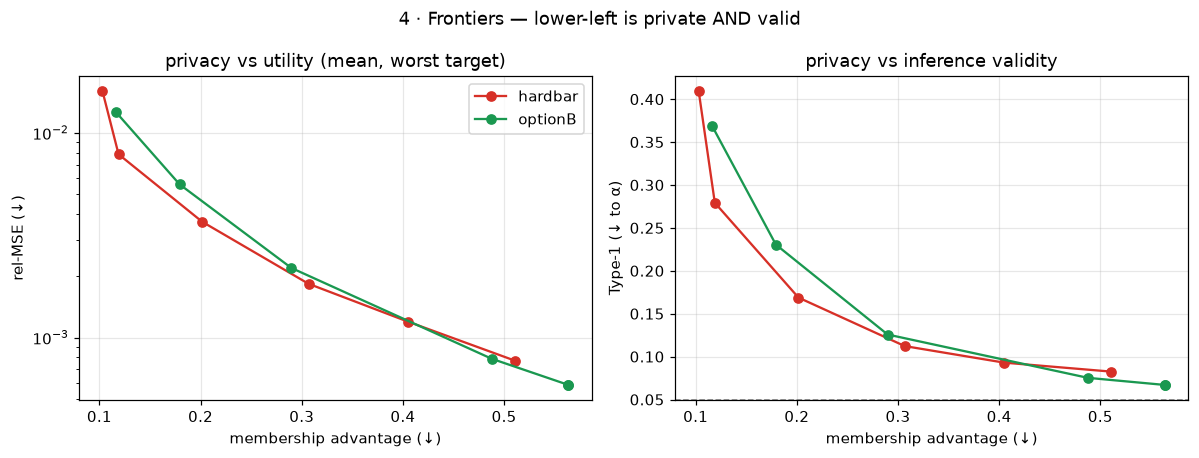

[read-off] hardbar sits at lower advantage (more private) for a given scale; optionB sits at lower Type-1 (more inference-valid). The privacy-vs-inference panel shows the trade: which mechanism reaches your target advantage at the lower Type-1.


In [7]:
# merge privacy (worst target, mean stat, 5x5x5) with inference by scale, per mechanism
piv = PU[(PU.target=="worst") & (PU.patch=="5x5x5") & (PU.stat=="mean")][["mech","scale","adv","rel_mse"]]
merged = piv.merge(INFR[["mech","scale","type1","power"]], on=["mech","scale"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for mech, col in zip(MECHS, ["#d73027","#1a9850"]):
    s = merged[merged.mech==mech].sort_values("scale")
    ax[0].plot(s.adv, s.rel_mse, "o-", color=col, label=mech)
    ax[1].plot(s.adv, s.type1, "o-", color=col, label=mech)
ax[1].axhline(0.05, ls="--", color="grey", lw=1)
ax[0].set_xlabel("membership advantage (↓)"); ax[0].set_ylabel("rel-MSE (↓)"); ax[0].set_yscale("log"); ax[0].legend()
ax[0].set_title("privacy vs utility (mean, worst target)")
ax[1].set_xlabel("membership advantage (↓)"); ax[1].set_ylabel("Type-1 (↓ to α)")
ax[1].set_title("privacy vs inference validity")
fig.suptitle("4 · Frontiers — lower-left is private AND valid"); plt.tight_layout(); plt.show()
print("[read-off] hardbar sits at lower advantage (more private) for a given scale; optionB sits at "
      "lower Type-1 (more inference-valid). The privacy-vs-inference panel shows the trade: which "
      "mechanism reaches your target advantage at the lower Type-1.")

## 5 · Read-off

- **Privacy**: expect **hardbar** lower advantage than optionB at a given scale — the per-draw floor
  covers the attack direction every draw; optionB's high-probability coverage occasionally under-covers.
- **Inference**: expect **optionB** closer to nominal Type-1 — it stays Gaussian; the hard bar's
  folded-tail noise inflates Type-1 more (both still inflate with raw magnitude at high scale).
- **The fork**: per-draw worst-case masking (hardbar, more private, less valid) vs high-probability
  masking (optionB, less private, more valid, Gaussian → a path to a *formal* DP guarantee). With the
  project's assumption of large samples (inference nick less critical), the hardbar's privacy edge may
  win — but now it is a measured trade-off to put to the supervisor, not an idea.

*Next: resume the full-release sweeps (SPEC_NB8) with the chosen (bar, mechanism).*